In [ ]:
# Cleaned environment setup

In [ ]:
# PDF extraction code removed as requested

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_regression, make_classification, make_blobs
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import (
    mean_squared_error, r2_score, accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix, silhouette_score
)
from scipy.cluster.hierarchy import dendrogram, linkage

# Set random seed for reproducibility
np.random.seed(42)

# -----------------------------------------------------
# DATA PREPARATION
# -----------------------------------------------------

# 1. Regression Dataset (for Linear, Ridge, Lasso Regression)
X_reg, y_reg = make_regression(n_samples=200, n_features=5, noise=15.0, random_state=42)
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

# 2. Classification Dataset (for Decision Trees, Logistic Reg, KNN, Naive Bayes, Ensembles)
X_cls, y_cls = make_classification(
    n_samples=300, n_features=4, n_informative=3, n_redundant=1,
    n_classes=2, weights=[0.4, 0.6], random_state=42
)
X_cls_train, X_cls_test, y_cls_train, y_cls_test = train_test_split(X_cls, y_cls, test_size=0.2, random_state=42)

# Scale classification features
scaler = StandardScaler()
X_cls_train_scaled = scaler.fit_transform(X_cls_train)
X_cls_test_scaled = scaler.transform(X_cls_test)

# 3. Clustering & Dimension Reduction Dataset
X_clust, y_clust_true = make_blobs(n_samples=150, n_features=4, centers=3, cluster_std=1.2, random_state=42)

print("Datasets initialized successfully!")

Datasets initialized successfully!


--- (a) Running Linear Regression with regularizations ---
Linear Regression Coefficients: [ 2.67149559 11.29338277 65.50544746 18.54352428 69.47629118] | Intercept: 1.4599
Ridge Regression Coefficients:  [ 2.70433015 11.22086054 65.08872514 18.40540461 69.01918896] | Intercept: 1.5118
Lasso Regression Coefficients:  [ 2.29930335 10.7926752  65.07639121 17.97367639 68.90989629] | Intercept: 1.5463

--- (b) Running Decision Tree Classifiers ---
Decision Tree (Gini) Depth: 3 | Leaves: 8
Decision Tree (Entropy) Depth: 3 | Leaves: 8

--- (c) Running Logistic Regression ---
L2 Logistic Regression Coefficients: [1.77393981 0.58769688 0.50447019 0.17859224] | Intercept: 0.7861
L1 Logistic Regression Coefficients: [1.8427485  0.32676351 0.78734992 0.        ] | Intercept: 0.7812

--- (d) Running K-NN Classifier ---
K-NN Classifier initialized with 5 neighbors and metric='minkowski'

--- (e) Running Naive Bayes Classifier ---
Naive Bayes Class Priors: [0.40833333 0.59166667]
Naive Bayes Feature

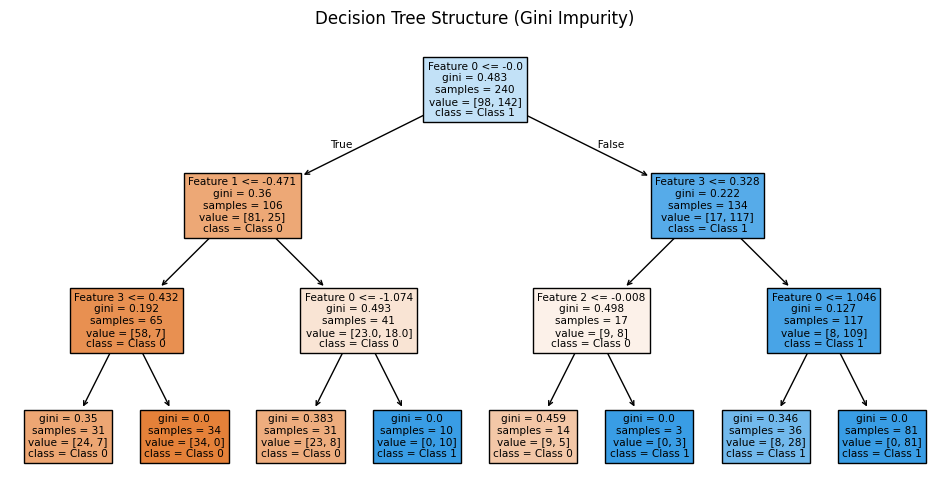

In [ ]:
# =====================================================
# QUESTION 1: Supervised Learning Models
# =====================================================

# (a) Linear Regression, Ridge, and Lasso
print("--- (a) Running Linear Regression with regularizations ---")
lin_reg = LinearRegression().fit(X_reg_train, y_reg_train)
ridge_reg = Ridge(alpha=1.0).fit(X_reg_train, y_reg_train)
lasso_reg = Lasso(alpha=0.5).fit(X_reg_train, y_reg_train)

print(f"Linear Regression Coefficients: {lin_reg.coef_} | Intercept: {lin_reg.intercept_:.4f}")
print(f"Ridge Regression Coefficients:  {ridge_reg.coef_} | Intercept: {ridge_reg.intercept_:.4f}")
print(f"Lasso Regression Coefficients:  {lasso_reg.coef_} | Intercept: {lasso_reg.intercept_:.4f}")

# (b) Decision Tree with different criteria
print("\n--- (b) Running Decision Tree Classifiers ---")
dt_gini = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42).fit(X_cls_train, y_cls_train)
dt_entropy = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42).fit(X_cls_train, y_cls_train)

print(f"Decision Tree (Gini) Depth: {dt_gini.get_depth()} | Leaves: {dt_gini.get_n_leaves()}")
print(f"Decision Tree (Entropy) Depth: {dt_entropy.get_depth()} | Leaves: {dt_entropy.get_n_leaves()}")

# (c) Logistic Regression with regularizations
print("\n--- (c) Running Logistic Regression ---")
log_reg_l2 = LogisticRegression(penalty='l2', solver='liblinear', C=1.0).fit(X_cls_train_scaled, y_cls_train)
log_reg_l1 = LogisticRegression(penalty='l1', solver='liblinear', C=1.0).fit(X_cls_train_scaled, y_cls_train)

print(f"L2 Logistic Regression Coefficients: {log_reg_l2.coef_[0]} | Intercept: {log_reg_l2.intercept_[0]:.4f}")
print(f"L1 Logistic Regression Coefficients: {log_reg_l1.coef_[0]} | Intercept: {log_reg_l1.intercept_[0]:.4f}")

# (d) K-NN Implementation
print("\n--- (d) Running K-NN Classifier ---")
knn = KNeighborsClassifier(n_neighbors=5).fit(X_cls_train_scaled, y_cls_train)
print(f"K-NN Classifier initialized with {knn.n_neighbors} neighbors and metric='{knn.metric}'")

# (e) Naive Bayes Implementation
print("\n--- (e) Running Naive Bayes Classifier ---")
nb = GaussianNB().fit(X_cls_train, y_cls_train)
print(f"Naive Bayes Class Priors: {nb.class_prior_}")
print(f"Naive Bayes Feature Means:\n{nb.theta_}")

# Visualization of a Decision Tree for part (b)
plt.figure(figsize=(12, 6))
plot_tree(dt_gini, filled=True, feature_names=[f'Feature {i}' for i in range(4)], class_names=['Class 0', 'Class 1'])
plt.title("Decision Tree Structure (Gini Impurity)")
plt.show()

--- (a) Running Clustering Algorithms ---
K-means Inertia: 813.5070
K-means Cluster Centers:
[[-6.81991525 -6.78822907 -8.67868455  7.30571344]
 [-2.64782581  9.01289656  4.45528263  2.03875246]
 [ 2.08890614  4.00343308 -9.65805111  9.28046198]]
Hierarchical Linkage Matrix shape: (149, 4)


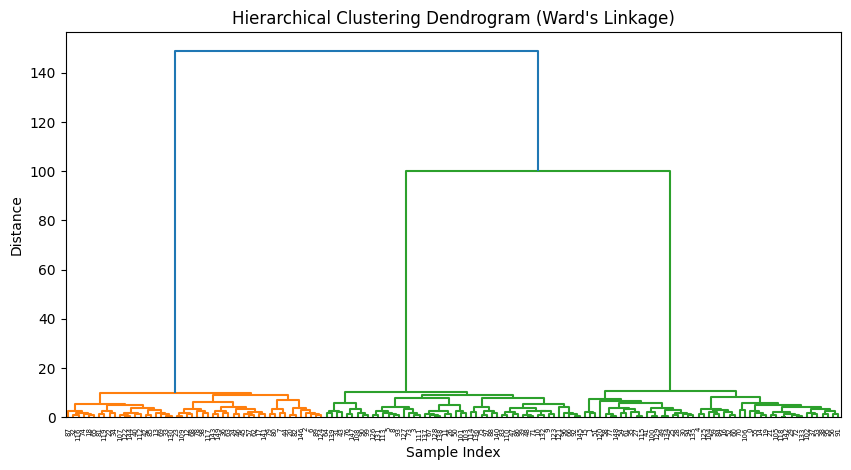


--- (b) Running Ensemble Methods ---
Random Forest - Out of 100 Estimators, trained successfully.
AdaBoost - Out of 100 Estimators, trained successfully.

--- (c) Running Gaussian Mixture Model ---
GMM Converged: True
GMM Means:
[[-6.81991525 -6.78822907 -8.67868455  7.30571344]
 [-2.64782581  9.01289656  4.45528263  2.03875246]
 [ 2.08890614  4.00343308 -9.65805111  9.28046198]]
GMM Weights: [0.33333333 0.33333333 0.33333333]

--- (d) Running PCA Dimensionality Reduction ---
Explained Variance Ratio: [0.71798295 0.25870369]
Total Explained Variance: 97.67%


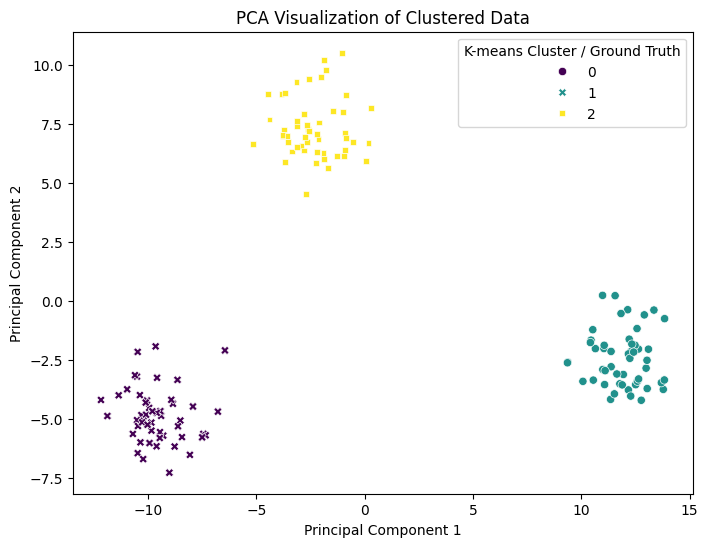

In [ ]:
# =====================================================
# QUESTION 2: Clustering, Ensembles & Dimensionality Reduction
# =====================================================

# (a) K-means and Hierarchical Clustering
print("--- (a) Running Clustering Algorithms ---")
kmeans = KMeans(n_clusters=3, random_state=42).fit(X_clust)
print(f"K-means Inertia: {kmeans.inertia_:.4f}")
print(f"K-means Cluster Centers:\n{kmeans.cluster_centers_}")

# Hierarchical linkage construction
linkage_matrix = linkage(X_clust, method='ward')
print(f"Hierarchical Linkage Matrix shape: {linkage_matrix.shape}")

# Dendrogram plot
plt.figure(figsize=(10, 5))
dendrogram(linkage_matrix)
plt.title("Hierarchical Clustering Dendrogram (Ward's Linkage)")
plt.xlabel("Sample Index")
plt.ylabel("Distance")
plt.show()

# (b) Ensemble Methods: Random Forest (Bagging) and AdaBoost (Boosting)
print("\n--- (b) Running Ensemble Methods ---")
rf = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_cls_train, y_cls_train)
adaboost = AdaBoostClassifier(n_estimators=100, random_state=42).fit(X_cls_train, y_cls_train)
print(f"Random Forest - Out of 100 Estimators, trained successfully.")
print(f"AdaBoost - Out of 100 Estimators, trained successfully.")

# (c) Gaussian Mixture Models (GMM)
print("\n--- (c) Running Gaussian Mixture Model ---")
gmm = GaussianMixture(n_components=3, random_state=42).fit(X_clust)
gmm_labels = gmm.predict(X_clust)
print(f"GMM Converged: {gmm.converged_}")
print(f"GMM Means:\n{gmm.means_}")
print(f"GMM Weights: {gmm.weights_}")

# (d) PCA and Visualization
print("\n--- (d) Running PCA Dimensionality Reduction ---")
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_clust)
print(f"Explained Variance Ratio: {pca.explained_variance_ratio_}")
print(f"Total Explained Variance: {sum(pca.explained_variance_ratio_)*100:.2f}%")

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=kmeans.labels_, palette='viridis', style=y_clust_true)
plt.title("PCA Visualization of Clustered Data")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="K-means Cluster / Ground Truth")
plt.show()

In [ ]:
# =====================================================
# QUESTION 3: Performance Analysis & Evaluation Metrics
# =====================================================

print("=== Performance Metrics Analysis ===\n")

# 1. Regression Metrics
for name, model in [("Linear Regression", lin_reg), ("Ridge Regression", ridge_reg), ("Lasso Regression", lasso_reg)]:
    preds = model.predict(X_reg_test)
    mse = mean_squared_error(y_reg_test, preds)
    r2 = r2_score(y_reg_test, preds)
    print(f"{name:20} -> MSE: {mse:.4f} | R² Score: {r2:.4f}")

print("\n" + "="*40 + "\n")

# 2. Classification Metrics
classifiers = [
    ("Decision Tree (Gini)", dt_gini, False),
    ("Decision Tree (Entropy)", dt_entropy, False),
    ("Logistic Reg (L2)", log_reg_l2, True),
    ("Logistic Reg (L1)", log_reg_l1, True),
    ("K-NN Classifier", knn, True),
    ("Naive Bayes", nb, False),
    ("Random Forest", rf, False),
    ("AdaBoost", adaboost, False)
]

for name, clf, is_scaled in classifiers:
    X_eval = X_cls_test_scaled if is_scaled else X_cls_test
    preds = clf.predict(X_eval)
    acc = accuracy_score(y_cls_test, preds)
    prec = precision_score(y_cls_test, preds)
    rec = recall_score(y_cls_test, preds)
    f1 = f1_score(y_cls_test, preds)
    print(f"{name:25} -> Accuracy: {acc:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f} | F1: {f1:.4f}")

print("\n" + "="*40 + "\n")

# 3. Clustering Metrics
silh_kmeans = silhouette_score(X_clust, kmeans.labels_)
silh_gmm = silhouette_score(X_clust, gmm_labels)
print(f"K-Means Silhouette Score: {silh_kmeans:.4f}")
print(f"GMM Silhouette Score:     {silh_gmm:.4f}")

=== Performance Metrics Analysis ===

Linear Regression    -> MSE: 191.3813 | R² Score: 0.9780
Ridge Regression     -> MSE: 189.3152 | R² Score: 0.9782
Lasso Regression     -> MSE: 189.1303 | R² Score: 0.9782


Decision Tree (Gini)      -> Accuracy: 0.8333 | Precision: 0.9355 | Recall: 0.7838 | F1: 0.8529
Decision Tree (Entropy)   -> Accuracy: 0.8333 | Precision: 0.9355 | Recall: 0.7838 | F1: 0.8529
Logistic Reg (L2)         -> Accuracy: 0.8333 | Precision: 0.8462 | Recall: 0.8919 | F1: 0.8684
Logistic Reg (L1)         -> Accuracy: 0.8333 | Precision: 0.8462 | Recall: 0.8919 | F1: 0.8684
K-NN Classifier           -> Accuracy: 0.8500 | Precision: 0.9375 | Recall: 0.8108 | F1: 0.8696
Naive Bayes               -> Accuracy: 0.8500 | Precision: 0.8889 | Recall: 0.8649 | F1: 0.8767
Random Forest             -> Accuracy: 0.8167 | Precision: 0.8824 | Recall: 0.8108 | F1: 0.8451
AdaBoost                  -> Accuracy: 0.8167 | Precision: 0.8611 | Recall: 0.8378 | F1: 0.8493


K-Means Silhouette 